# Getting started: analyze the C12666MA spectra

This notebook loads the openJII JSON download, checks the recorded devices and sessions, plots a spectrum, and compares signal in wavelength bands over time. Spectra and dark references are normalized by integration time, then each spectrum has its matching sensor's mean dark spectrum subtracted pixel-by-pixel. All dark rows in the download are used, even when the plots are limited to a smaller time range. Corrected rates can be negative from measurement noise and are not an absolute fluorescence yield.

In [62]:
import json
from pathlib import Path
%matplotlib ipympl
import matplotlib.pyplot as plt

import numpy as np
import pandas as pd

json_path = Path(r"C:\\Users\\tolsm012\\C12666MA data\\spectrometer-Kjell_openjii_2026-11-16_13-50-57.json")

with json_path.open(encoding="utf-8") as file:
    download = json.load(file)

table_name = "c12666ma_spectra"
table = next(t for t in download["tables"] if t["name"] == table_name)
rows = table["rows"]
spectra = pd.DataFrame(row for row in rows if row.get("kind") == "spectrum")
dark_rows = [row for row in rows if row.get("kind") == "dark"]

# Choose a time range in local time. Leave either value empty for no limit.
# Example: start_datetime = "2026-11-02 15:00:00"
#          end_datetime   = "2026-11-02 16:00:00"
local_timezone = "Europe/Amsterdam"
start_datetime = "2026-11-13 13:00:00"
end_datetime = "2026-11-16 16:30:00"

spectra["timestamp"] = pd.to_datetime(spectra["timestamp_utc"], utc=True)
spectra["timestamp_local"] = spectra["timestamp"].dt.tz_convert(local_timezone)

if not dark_rows:
    raise ValueError("This download has no dark-reference rows; dark subtraction cannot be applied")
dark_spectra = pd.DataFrame(dark_rows)

def normalized_rate(row, count_field, label):
    integration_s = pd.to_numeric(row["integration_us"], errors="coerce") / 1_000_000
    if pd.isna(integration_s) or integration_s <= 0:
        raise ValueError(f"{label} must have a positive integration_us value")
    counts = np.asarray(row[count_field], dtype=float)
    wavelengths = np.asarray(row["wavelength_nm"], dtype=float)
    if counts.ndim != 1 or counts.size != wavelengths.size:
        raise ValueError(f"{label} counts and wavelength arrays must have matching lengths")
    return (counts / integration_s).tolist()

def dark_profile_key(row):
    device_id = row.get("device_uid") or row["device_name"]
    wavelength_grid = tuple(np.asarray(row["wavelength_nm"], dtype=float))
    return (device_id, row.get("gain"), row.get("high_gain"), wavelength_grid)

# Dark rows store their averaged pixel values in counts_mean; use every dark row
# in the download, regardless of the selected plotting time range.
spectra["counts_per_s_raw"] = spectra.apply(
    lambda row: normalized_rate(row, "counts", "Every spectrum"), axis=1
)
dark_spectra["dark_rate_counts_per_s"] = dark_spectra.apply(
    lambda row: normalized_rate(row, "counts_mean", "Every dark reference"), axis=1
)
dark_rates_by_profile = {}
for _, row in dark_spectra.iterrows():
    dark_rates_by_profile.setdefault(dark_profile_key(row), []).append(
        np.asarray(row["dark_rate_counts_per_s"], dtype=float)
    )
dark_baselines = {
    key: np.mean(np.stack(rates), axis=0)
    for key, rates in dark_rates_by_profile.items()
}
missing_dark_profiles = spectra[
    ~spectra.apply(lambda row: dark_profile_key(row) in dark_baselines, axis=1)
]
if not missing_dark_profiles.empty:
    missing_devices = sorted(missing_dark_profiles["device_name"].dropna().unique())
    raise ValueError(f"No matching dark reference for spectrum device(s): {missing_devices}")

spectra["dark_rate_counts_per_s"] = spectra.apply(
    lambda row: dark_baselines[dark_profile_key(row)].tolist(), axis=1
)
spectra["counts_per_s"] = spectra.apply(
    lambda row: (
        np.asarray(row["counts_per_s_raw"], dtype=float)
        - np.asarray(row["dark_rate_counts_per_s"], dtype=float)
    ).tolist(),
    axis=1,
)

def parse_local_bound(value):
    if not value.strip():
        return None
    bound = pd.Timestamp(value)
    if bound.tzinfo is None:
        return bound.tz_localize(local_timezone)
    return bound.tz_convert(local_timezone)

start_bound = parse_local_bound(start_datetime)
end_bound = parse_local_bound(end_datetime)
if start_bound is not None and end_bound is not None and start_bound > end_bound:
    raise ValueError("start_datetime must be earlier than or equal to end_datetime")

selected = pd.Series(True, index=spectra.index)
if start_bound is not None:
    selected &= spectra["timestamp_local"] >= start_bound
if end_bound is not None:
    selected &= spectra["timestamp_local"] <= end_bound
spectra = spectra.loc[selected].copy()
if spectra.empty:
    raise ValueError("No spectra fall within this date/time range. Check the range and timezone.")

print(f"Experiment: {download['experiment']['name']}")
print(f"Table: {table_name}; spectra in selected range: {len(spectra)}; dark references: {len(dark_rows)}")
print(f"Selected local time: {spectra['timestamp_local'].min()} to {spectra['timestamp_local'].max()}")
print("Devices:", sorted(spectra["device_name"].dropna().unique()))
print(f"Applied pixel-wise dark subtraction using {len(dark_rows)} dark reference(s) from the full download.")

Experiment: spectrometer-Kjell
Table: c12666ma_spectra; spectra in selected range: 34560; dark references: 2
Selected local time: 2026-11-13 13:23:11.139000+01:00 to 2026-11-16 13:22:56.500000+01:00
Devices: ['Fluor', 'Top']
Applied pixel-wise dark subtraction using 2 dark reference(s) from the full download.


In [63]:
# Quick overview: which sessions/devices are present, and when they were recorded.
overview = (
    spectra.groupby(["session_id", "device_name"])
    .agg(spectra=("tick", "count"), first_seen=("timestamp_local", "min"), last_seen=("timestamp_local", "max"))
    .reset_index()
)
overview

,session_id,device_name,spectra,first_seen,last_seen
0,spectrometer-Kjell_2026-11-13_13-23-10,Fluor,17280,2026-11-13 13:23:11.139000+01:00,2026-11-16 13:22:56.300000+01:00
1,spectrometer-Kjell_2026-11-13_13-23-10,Top,17280,2026-11-13 13:23:11.340000+01:00,2026-11-16 13:22:56.500000+01:00


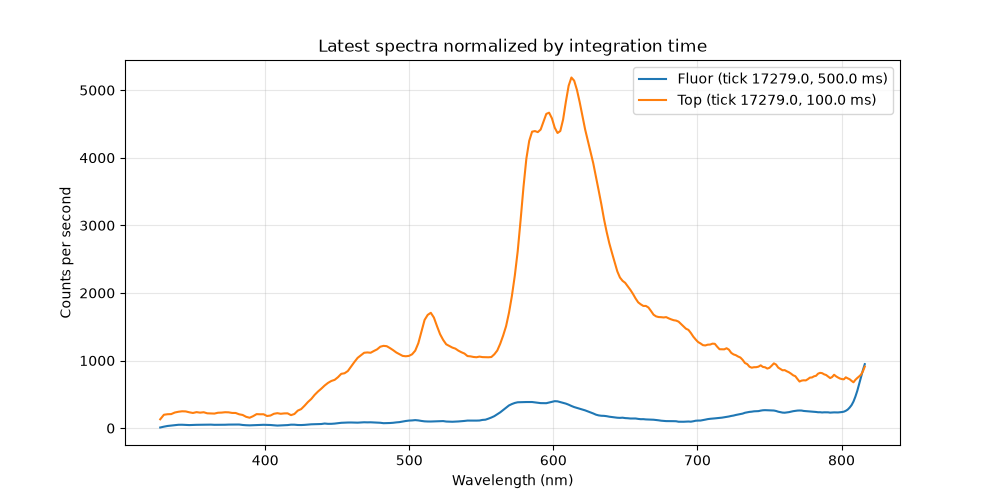

In [64]:
# Plot the latest spectrum from each spectrometer.
fig, ax = plt.subplots(figsize=(10, 5))
for device in sorted(spectra["device_name"].dropna().unique()):
    latest = (
        spectra[spectra["device_name"] == device]
        .sort_values("timestamp")
        .iloc[-1]
    )
    ax.plot(latest["wavelength_nm"], latest["counts_per_s"], label=f"{device} (tick {latest['tick']}, {latest['integration_ms']} ms)")

ax.set(title="Latest spectra normalized by integration time", xlabel="Wavelength (nm)", ylabel="Counts per second")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

In [65]:
# Choose each signal's spectrometer and wavelength range independently.
incident_device = "Top"
incident_range_nm = (760, 770)
fluorescence_device = "Fluor"
fluorescence_range_nm = (760, 770)
par_device = "Top"
par_range_nm = (400, 700)

def sum_in_band(row, wavelength_range):
    wavelengths = np.asarray(row["wavelength_nm"], dtype=float)
    counts_per_s = np.asarray(row["counts_per_s"], dtype=float)
    mask = (wavelengths >= wavelength_range[0]) & (wavelengths <= wavelength_range[1])
    if not mask.any():
        return np.nan
    return counts_per_s[mask].sum()

def band_rates(device, wavelength_range, rate_name):
    device_spectra = spectra.loc[spectra["device_name"] == device].copy()
    if device_spectra.empty:
        raise ValueError(f"No spectra found for selected device: {device!r}")
    device_spectra[rate_name] = device_spectra.apply(
        lambda row: sum_in_band(row, wavelength_range), axis=1
    )
    return device_spectra.groupby(["session_id", "tick"], as_index=False).agg(
        **{rate_name: (rate_name, "first"), f"{rate_name}_timestamp": ("timestamp", "mean")}
    )

keys = ["session_id", "tick"]
incident_rates = band_rates(incident_device, incident_range_nm, "incident_rate")
fluorescence_rates = band_rates(fluorescence_device, fluorescence_range_nm, "fluorescence_rate")
par_rates = band_rates(par_device, par_range_nm, "par_rate").drop(columns="par_rate_timestamp")

# Pair incident and fluorescence readings by session and synchronized trigger.
paired = incident_rates.merge(fluorescence_rates, on=keys, how="inner", validate="one_to_one")
paired["timestamp"] = paired[["incident_rate_timestamp", "fluorescence_rate_timestamp"]].mean(axis=1)
paired = paired.drop(columns=["incident_rate_timestamp", "fluorescence_rate_timestamp"])
paired = paired.merge(par_rates, on=keys, how="left", validate="one_to_one")
paired["rate_ratio"] = paired["fluorescence_rate"] / paired["incident_rate"].where(paired["incident_rate"] > 0)
paired = paired.sort_values("timestamp")
paired["timestamp_local"] = paired["timestamp"].dt.tz_convert(local_timezone)
paired[["timestamp_local", "session_id", "tick", "incident_rate", "fluorescence_rate", "par_rate", "rate_ratio"]].head()

,timestamp_local,session_id,tick,incident_rate,fluorescence_rate,par_rate,rate_ratio
0,2026-11-13 13:23:11.239500+01:00,spectrometer-Kjell_2026-11-13_13-23-10,0.0,6329.0,2210.4,332723.5,0.349249
1,2026-11-13 13:23:26.240500+01:00,spectrometer-Kjell_2026-11-13_13-23-10,1.0,6479.0,2466.4,339623.5,0.380676
2,2026-11-13 13:23:41.240500+01:00,spectrometer-Kjell_2026-11-13_13-23-10,2.0,6239.0,2182.4,334463.5,0.349800
3,2026-11-13 13:23:56.240000+01:00,spectrometer-Kjell_2026-11-13_13-23-10,3.0,6089.0,2048.4,326073.5,0.336410
4,2026-11-13 13:24:11.240500+01:00,spectrometer-Kjell_2026-11-13_13-23-10,4.0,6629.0,2234.4,335253.5,0.337064


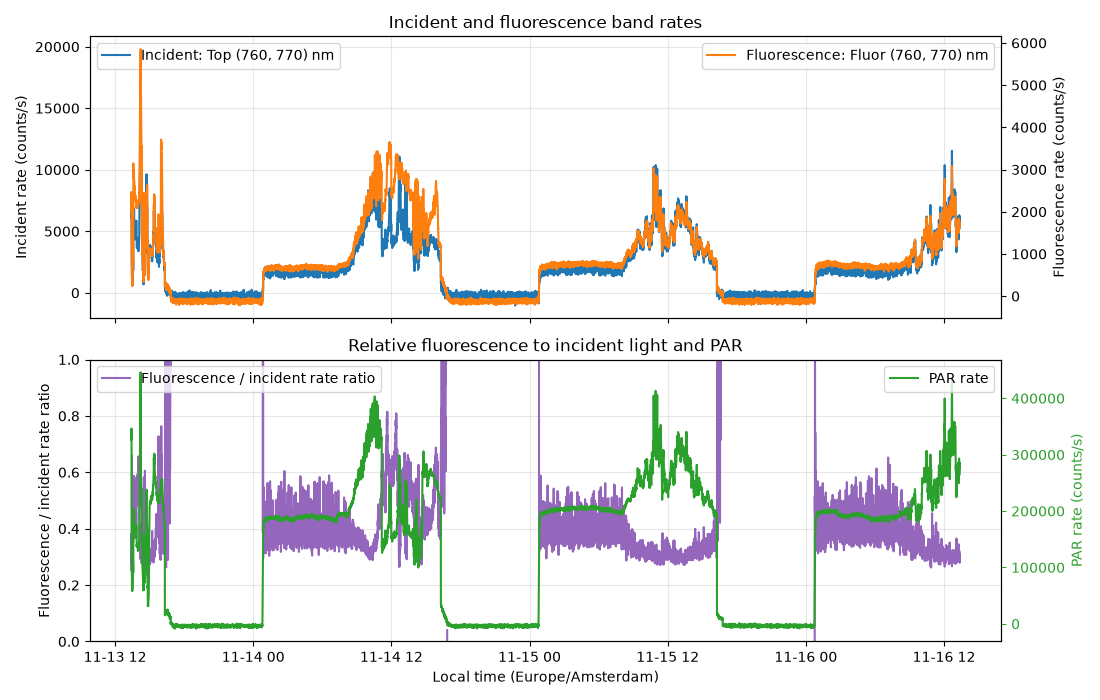

In [66]:
# Plot incident and fluorescence bands, PAR, and their ratio over time.
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

axes[0].set(title="Incident and fluorescence band rates")
axes[0].plot(
    paired["timestamp_local"], paired["incident_rate"],
    label=f"Incident: {incident_device} {incident_range_nm} nm", color="tab:blue",
)
axes[0].set_ylabel("Incident rate (counts/s)")
axes[0].legend(loc="upper left")

fluorescence_ax = axes[0].twinx()
fluorescence_ax.plot(
    paired["timestamp_local"], paired["fluorescence_rate"],
    label=f"Fluorescence: {fluorescence_device} {fluorescence_range_nm} nm",
    color="tab:orange",
)
fluorescence_ax.set_ylabel("Fluorescence rate (counts/s)")
fluorescence_ax.legend(loc="upper right")

axes[1].set(title="Relative fluorescence to incident light and PAR")
ratio_line, = axes[1].plot(
    paired["timestamp_local"], paired["rate_ratio"],
    label="Fluorescence / incident rate ratio", color="tab:purple",
)
axes[1].set_ylabel("Fluorescence / incident rate ratio")
axes[1].set_ylim(0, 1)
axes[1].legend(handles=[ratio_line], loc="upper left")

par_ax = axes[1].twinx()
par_line, = par_ax.plot(
    paired["timestamp_local"], paired["par_rate"],
    label="PAR rate", color="tab:green",
)
par_ax.set_ylabel("PAR rate (counts/s)", color="tab:green")
par_ax.tick_params(axis="y", colors="tab:green")
par_ax.legend(handles=[par_line], loc="upper right")

axes[1].set_xlabel(f"Local time ({local_timezone})")
for ax in axes:
    ax.grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

## Analyze wavelength blocks

This is an additional analysis; it does not change the plots above. Choose the wavelength interval and block width below. For each spectrometer, the notebook sums the counts-per-second values of pixels in each wavelength block, plots each block over time, and compares the mean block rate. These values are not dark-corrected.

In [73]:
# Tune these settings. The end of the range is included; the last block may be shorter.
block_wavelength_range_nm = (400, 600)
block_width_nm = 10
block_devices = [incident_device, fluorescence_device]

range_start_nm, range_end_nm = block_wavelength_range_nm
if range_start_nm >= range_end_nm:
    raise ValueError("The block wavelength range must have a positive width")
if block_width_nm <= 0:
    raise ValueError("block_width_nm must be positive")
missing_devices = set(block_devices) - set(spectra["device_name"].unique())
if missing_devices:
    raise ValueError(f"No spectra found for selected devices: {sorted(missing_devices)}")

block_edges = np.arange(range_start_nm, range_end_nm, block_width_nm, dtype=float)
block_edges = np.append(block_edges, range_end_nm)
block_records = []
for _, row in spectra[spectra["device_name"].isin(block_devices)].iterrows():
    wavelengths = np.asarray(row["wavelength_nm"], dtype=float)
    rates = np.asarray(row["counts_per_s"], dtype=float)
    for lower, upper in zip(block_edges[:-1], block_edges[1:]):
        # Include the final range endpoint in the last block.
        in_block = (wavelengths >= lower) & (wavelengths < upper)
        if upper == range_end_nm:
            in_block |= wavelengths == upper
        rate = rates[in_block].sum() if in_block.any() else np.nan
        block_records.append({
            "session_id": row["session_id"],
            "tick": row["tick"],
            "timestamp_local": row["timestamp_local"],
            "device_name": row["device_name"],
            "block_start_nm": lower,
            "block_end_nm": upper,
            "block_label": f"{lower:g}-{upper:g} nm",
            "rate_counts_per_s": rate,
        })

block_rates = pd.DataFrame(block_records)
block_summary = (
    block_rates.dropna(subset=["rate_counts_per_s"])
    .groupby(["device_name", "block_label"], as_index=False)
    .agg(mean_rate_counts_per_s=("rate_counts_per_s", "mean"),
         median_rate_counts_per_s=("rate_counts_per_s", "median"),
         spectra=("rate_counts_per_s", "count"))
)
block_summary

,device_name,block_label,mean_rate_counts_per_s,median_rate_counts_per_s,spectra
0,Fluor,400-410 nm,82.973032,94.8,17280
1,Fluor,410-420 nm,82.564468,89.8,17280
2,Fluor,420-430 nm,118.084838,110.5,17280
3,Fluor,430-440 nm,112.278588,99.5,17280
4,Fluor,440-450 nm,125.547569,109.5,17280
5,Fluor,450-460 nm,188.915625,167.3,17280
6,Fluor,460-470 nm,149.988194,127.7,17280
7,Fluor,470-480 nm,175.632407,142.4,17280
8,Fluor,480-490 nm,131.025926,86.9,17280
9,Fluor,490-500 nm,208.014699,169.9,17280


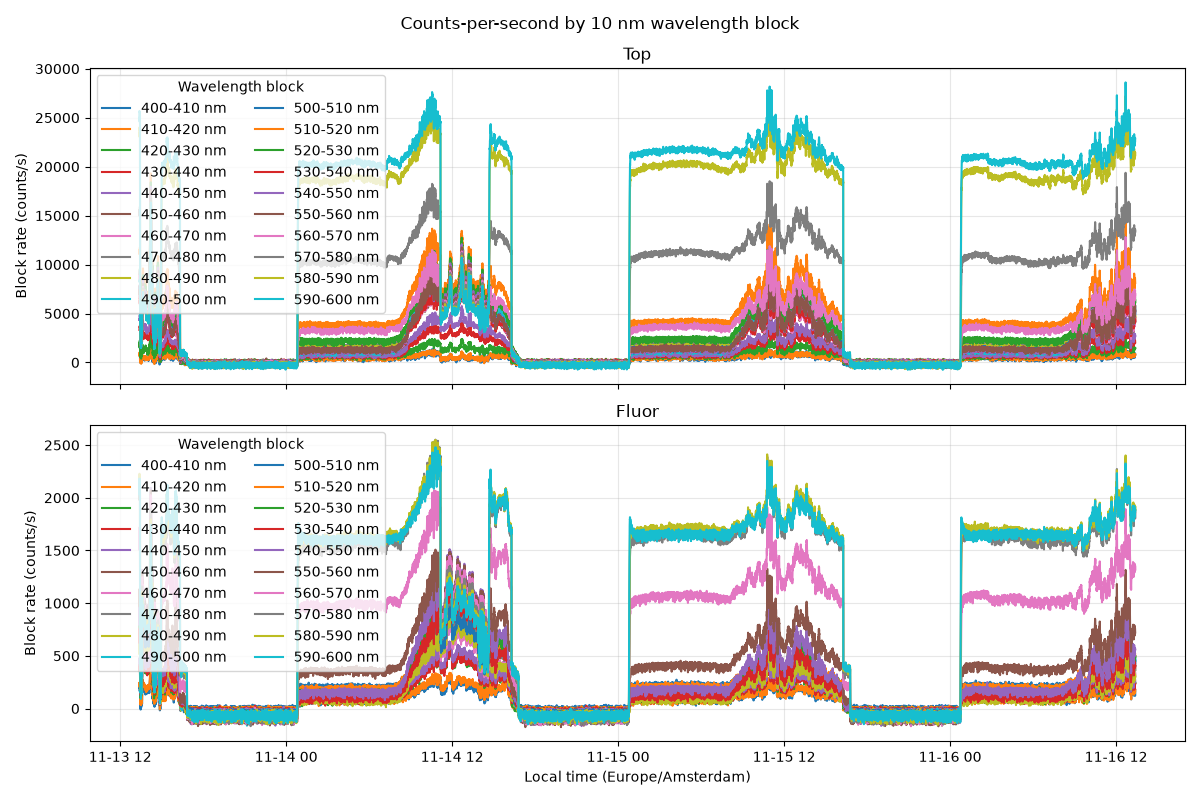

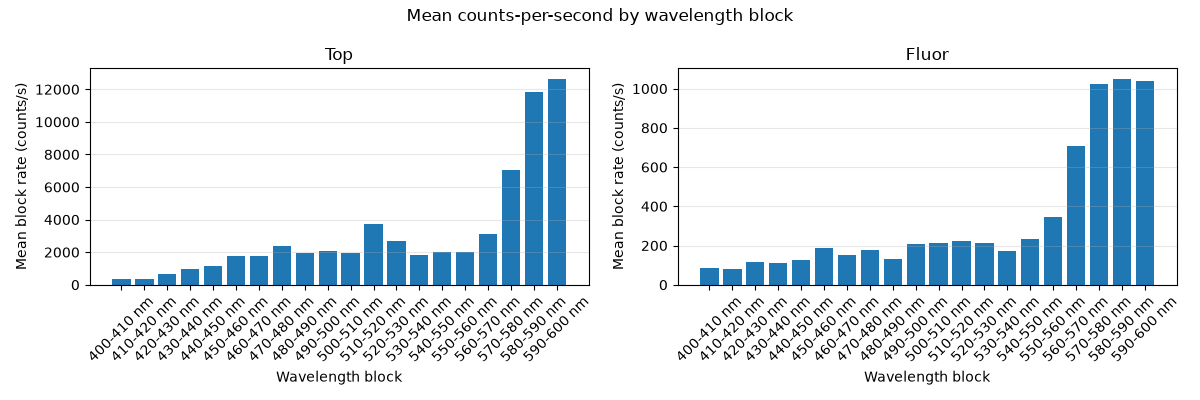

In [74]:
# One line per wavelength block, in separate panels for the selected devices.
fig, axes = plt.subplots(len(block_devices), 1, figsize=(12, 4 * len(block_devices)),
                         sharex=True, squeeze=False)
for ax, device in zip(axes[:, 0], block_devices):
    device_data = block_rates[block_rates["device_name"] == device]
    for label, block in device_data.groupby("block_label", sort=False):
        block = block.sort_values("timestamp_local")
        ax.plot(block["timestamp_local"], block["rate_counts_per_s"], label=label)
    ax.set_title(device)
    ax.set_ylabel("Block rate (counts/s)")
    ax.legend(title="Wavelength block", ncol=2)
    ax.grid(True, alpha=0.3)
axes[-1, 0].set_xlabel(f"Local time ({local_timezone})")
fig.suptitle(f"Counts-per-second by {block_width_nm:g} nm wavelength block")
fig.tight_layout()
plt.show()

# Compare each block's average rate over the selected date/time range.
fig, axes = plt.subplots(1, len(block_devices), figsize=(6 * len(block_devices), 4),
                         squeeze=False)
for ax, device in zip(axes[0], block_devices):
    device_summary = block_summary[block_summary["device_name"] == device]
    ax.bar(device_summary["block_label"], device_summary["mean_rate_counts_per_s"])
    ax.set_title(device)
    ax.set_xlabel("Wavelength block")
    ax.set_ylabel("Mean block rate (counts/s)")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(True, axis="y", alpha=0.3)
fig.suptitle("Mean counts-per-second by wavelength block")
fig.tight_layout()
plt.show()

In [29]:
block_rates

,session_id,tick,timestamp_local,device_name,block_start_nm,block_end_nm,block_label,rate_counts_per_s
0,spectrometer-Kjell_2026-11-13_13-23-10,4564.0,2026-11-14 08:24:11.250000+01:00,Fluor,400.0,450.0,400-450 nm,692.1
1,spectrometer-Kjell_2026-11-13_13-23-10,4564.0,2026-11-14 08:24:11.250000+01:00,Fluor,450.0,500.0,450-500 nm,990.2
2,spectrometer-Kjell_2026-11-13_13-23-10,4564.0,2026-11-14 08:24:11.250000+01:00,Fluor,500.0,550.0,500-550 nm,1283.9
3,spectrometer-Kjell_2026-11-13_13-23-10,4564.0,2026-11-14 08:24:11.250000+01:00,Fluor,550.0,600.0,550-600 nm,6533.0
4,spectrometer-Kjell_2026-11-13_13-23-10,4564.0,2026-11-14 08:24:11.250000+01:00,Fluor,600.0,650.0,600-650 nm,5667.3
...,...,...,...,...,...,...,...,...
276475,spectrometer-Kjell_2026-11-13_13-23-10,13576.0,2026-11-15 21:57:11.300000+01:00,Fluor,550.0,600.0,550-600 nm,-433.0
276476,spectrometer-Kjell_2026-11-13_13-23-10,13576.0,2026-11-15 21:57:11.300000+01:00,Fluor,600.0,650.0,600-650 nm,-356.7
276477,spectrometer-Kjell_2026-11-13_13-23-10,13576.0,2026-11-15 21:57:11.300000+01:00,Fluor,650.0,700.0,650-700 nm,-379.3
276478,spectrometer-Kjell_2026-11-13_13-23-10,13576.0,2026-11-15 21:57:11.300000+01:00,Fluor,700.0,750.0,700-750 nm,-493.5


## Compare spectrometers with scatter plots

Each dot is a synchronized measurement pair. The first plot compares the existing Top and Fluor wavelength-band rates. The second compares rates from the same wavelength block on both sensors; set `comparison_block_label` to focus on one block or leave it as `None` to show every block with a separate color. These are exploratory comparisons: sensor response and baseline can differ.

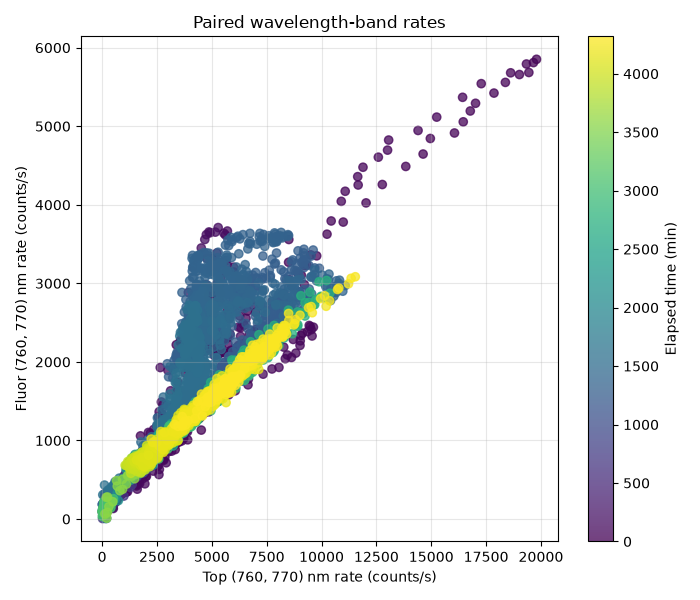

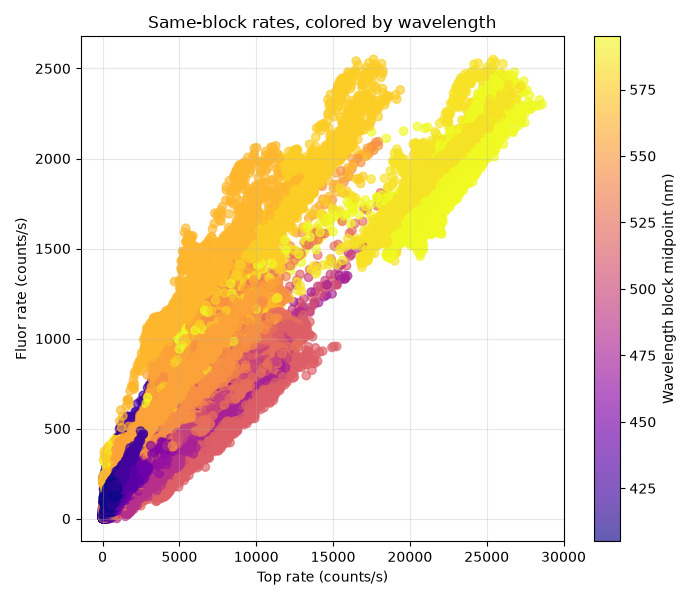

Paired band points: 11436; paired block points: 231869


In [75]:
# Compare incident and fluorescence band rates.

# Exclude paired measurements with missing, non-finite, or negative rates.
paired = paired.dropna(subset=["incident_rate", "fluorescence_rate"]).copy()
paired = paired[
    np.isfinite(paired["incident_rate"])
    & np.isfinite(paired["fluorescence_rate"])
    & (paired["incident_rate"] >= 0)
    & (paired["fluorescence_rate"] >= 0)
]

# Exclude missing, non-finite, or negative wavelength-block rates.
block_rates = block_rates.dropna(subset=["rate_counts_per_s"]).copy()
block_rates = block_rates[
    np.isfinite(block_rates["rate_counts_per_s"])
    & (block_rates["rate_counts_per_s"] >= 0)
]
block_rates = block_rates.dropna(subset=["rate_counts_per_s"]).copy()
block_rates = block_rates[np.isfinite(block_rates["rate_counts_per_s"])]
band_pairs = paired.dropna(subset=["incident_rate", "fluorescence_rate"]).copy()
band_pairs["elapsed_min"] = (
    band_pairs["timestamp"] - band_pairs["timestamp"].min()
).dt.total_seconds() / 60
fig, ax = plt.subplots(figsize=(7, 6))
scatter = ax.scatter(
    band_pairs["incident_rate"], band_pairs["fluorescence_rate"],
    c=band_pairs["elapsed_min"],
    cmap="viridis", alpha=0.75,
)
fig.colorbar(scatter, ax=ax, label="Elapsed time (min)")
ax.set_xlabel(f"{incident_device} {incident_range_nm} nm rate (counts/s)")
ax.set_ylabel(f"{fluorescence_device} {fluorescence_range_nm} nm rate (counts/s)")
ax.set_title("Paired wavelength-band rates")
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

# Compare the same wavelength block on both spectrometers.
# Example: comparison_block_label = "650-700 nm"; None shows every block.
comparison_block_label = None
block_pairs = block_rates.pivot_table(
    index=["session_id", "tick", "block_label", "block_start_nm", "block_end_nm"],
    columns="device_name", values="rate_counts_per_s", aggfunc="first",
).reset_index()
block_pairs = block_pairs.dropna(subset=[incident_device, fluorescence_device])
if comparison_block_label is not None:
    block_pairs = block_pairs[block_pairs["block_label"] == comparison_block_label]
    if block_pairs.empty:
        raise ValueError(f"No paired data for wavelength block {comparison_block_label!r}")
if block_pairs.empty:
    raise ValueError("No matching wavelength blocks have data from both spectrometers")

block_pairs["block_mid_nm"] = (block_pairs["block_start_nm"] + block_pairs["block_end_nm"]) / 2
fig, ax = plt.subplots(figsize=(7, 6))
scatter = ax.scatter(
    block_pairs[incident_device], block_pairs[fluorescence_device],
    c=block_pairs["block_mid_nm"], cmap="plasma", alpha=0.65,
)
fig.colorbar(scatter, ax=ax, label="Wavelength block midpoint (nm)")
ax.set_xlabel(f"{incident_device} rate (counts/s)")
ax.set_ylabel(f"{fluorescence_device} rate (counts/s)")
title = (f"Same-block rates ({comparison_block_label})" if comparison_block_label
         else "Same-block rates, colored by wavelength")
ax.set_title(title)
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

print(f"Paired band points: {len(band_pairs)}; paired block points: {len(block_pairs)}")

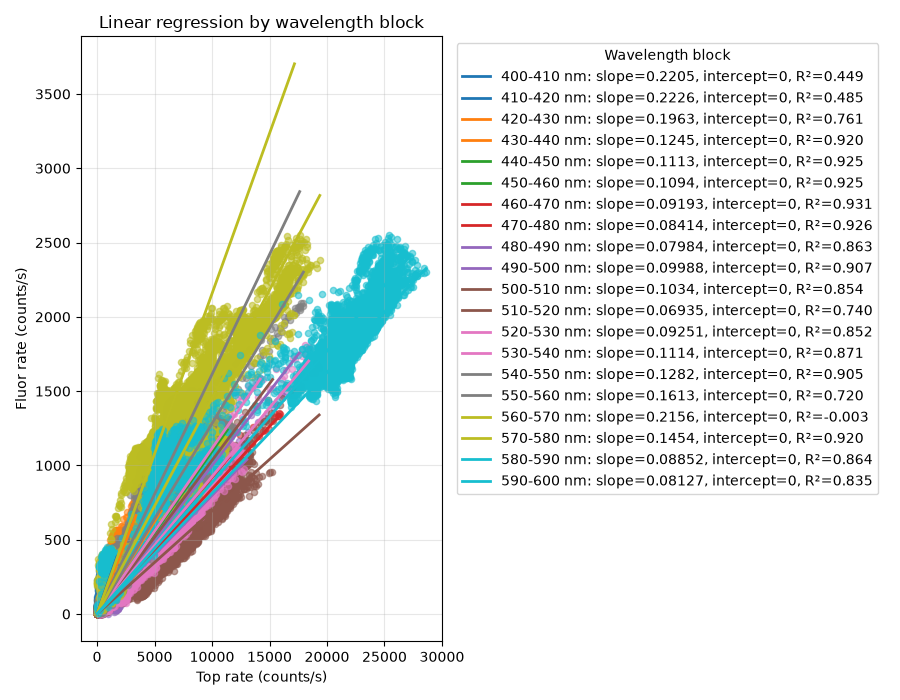

,block_label,points,slope,intercept,r_squared
0,400-410 nm,12224,0.220535,0.0,0.449321
1,410-420 nm,12007,0.222568,0.0,0.484638
2,420-430 nm,11602,0.196256,0.0,0.761173
3,430-440 nm,11695,0.124527,0.0,0.920472
4,440-450 nm,11561,0.111254,0.0,0.925269
5,450-460 nm,11541,0.109403,0.0,0.925416
6,460-470 nm,11522,0.091926,0.0,0.931461
7,470-480 nm,11511,0.084140,0.0,0.926048
8,480-490 nm,11464,0.079836,0.0,0.863266
9,490-500 nm,11482,0.099882,0.0,0.907195


In [77]:
# Fit and plot one linear regression per selected wavelength block.
blocks_to_fit = None  # Example: ["400-450 nm", "500-550 nm"]; None fits all
block_fit_x_range = None  # Example: (750, 2000); None uses all x values
block_fit_y_range = None  # Example: (100, 1000); None uses all y values
forced_intercept = 0  # Example: 0; None fits each intercept freely

if block_pairs.empty:
    raise ValueError("No paired wavelength-block data available")

available_blocks = set(block_pairs["block_label"].unique())
if blocks_to_fit is not None:
    unknown_blocks = set(blocks_to_fit) - available_blocks
    if unknown_blocks:
        raise ValueError(f"Unknown wavelength block(s): {sorted(unknown_blocks)}")
    if not blocks_to_fit:
        raise ValueError("blocks_to_fit cannot be an empty list")

block_regression_results = []
fig, ax = plt.subplots(figsize=(9, 7))

groups = block_pairs.groupby("block_label", sort=True)
if blocks_to_fit is not None:
    groups = [
        (label, group)
        for label, group in groups
        if label in blocks_to_fit
    ]

colors = plt.cm.tab10(np.linspace(0, 1, max(len(groups), 1)))

for color, (label, group) in zip(colors, groups):
    x_block = group[incident_device].to_numpy(dtype=float)
    y_block = group[fluorescence_device].to_numpy(dtype=float)

    valid = np.isfinite(x_block) & np.isfinite(y_block)
    if block_fit_x_range is not None:
        valid &= (x_block >= block_fit_x_range[0]) & (x_block <= block_fit_x_range[1])
    if block_fit_y_range is not None:
        valid &= (y_block >= block_fit_y_range[0]) & (y_block <= block_fit_y_range[1])

    x_fit_data = x_block[valid]
    y_fit_data = y_block[valid]

    if len(x_fit_data) < 2:
        print(f"Skipping {label}: need at least two valid points.")
        continue

    if forced_intercept is None:
        if np.ptp(x_fit_data) == 0:
            print(f"Skipping {label}: x values do not vary.")
            continue
        slope, intercept = np.polyfit(x_fit_data, y_fit_data, 1)
    else:
        intercept = float(forced_intercept)
        denominator = np.sum(x_fit_data**2)
        if denominator == 0:
            print(f"Skipping {label}: cannot fit a slope when all x values are zero.")
            continue
        slope = np.sum(x_fit_data * (y_fit_data - intercept)) / denominator

    predicted = slope * x_fit_data + intercept
    ss_res = np.sum((y_fit_data - predicted) ** 2)
    ss_total = np.sum((y_fit_data - y_fit_data.mean()) ** 2)
    r_squared = 1 - ss_res / ss_total if ss_total > 0 else np.nan

    ax.scatter(x_fit_data, y_fit_data, color=color, alpha=0.55, s=20)
    x_line = np.array([x_fit_data.min(), x_fit_data.max()])
    ax.plot(
        x_line,
        slope * x_line + intercept,
        color=color,
        linewidth=2,
        label=f"{label}: slope={slope:.4g}, intercept={intercept:.4g}, R²={r_squared:.3f}",
    )

    block_regression_results.append({
        "block_label": label,
        "points": len(x_fit_data),
        "slope": slope,
        "intercept": intercept,
        "r_squared": r_squared,
    })

ax.set_xlabel(f"{incident_device} rate (counts/s)")
ax.set_ylabel(f"{fluorescence_device} rate (counts/s)")
ax.set_title("Linear regression by wavelength block")
ax.grid(True, alpha=0.3)
if block_regression_results:
    ax.legend(title="Wavelength block", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()

block_regression_summary = pd.DataFrame(block_regression_results)
block_regression_summary


In [81]:
block_regression_summary["slope"]

0     0.220535
1     0.222568
2     0.196256
3     0.124527
4     0.111254
5     0.109403
6     0.091926
7     0.084140
8     0.079836
9     0.099882
10    0.103375
11    0.069353
12    0.092508
13    0.111429
14    0.128194
15    0.161299
16    0.215635
17    0.145392
18    0.088518
19    0.081271
Name: slope, dtype: float64

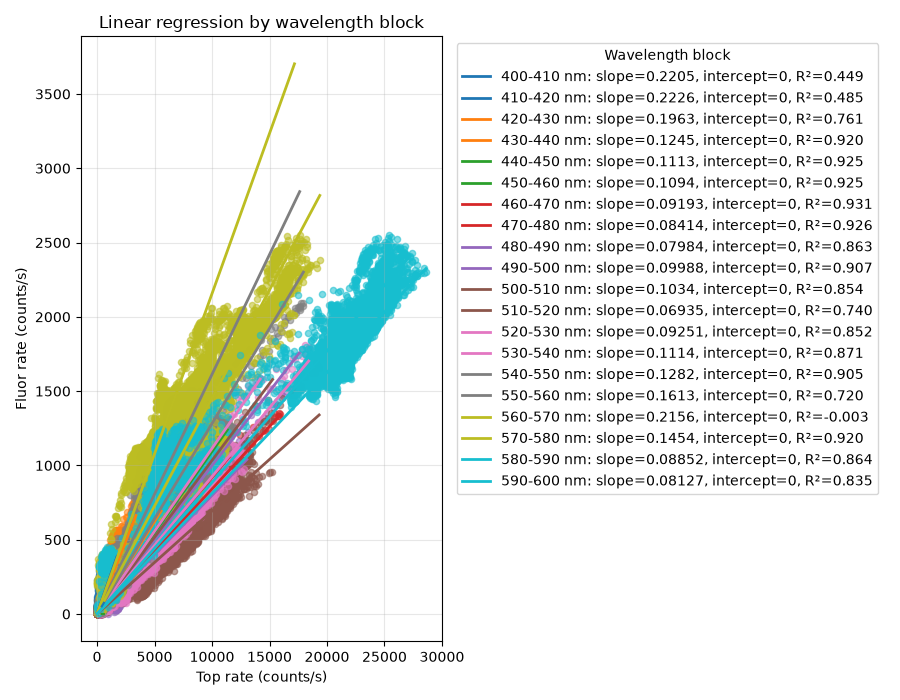

In [ ]:
x_slope = np.linspace(405, 595, 20)
y_slope = block_regression_summary["slope"]   
plt.plot(x_slope, y_slope)
plt.figure()
plt.plot(x_slope, y_slope)
plt.show()

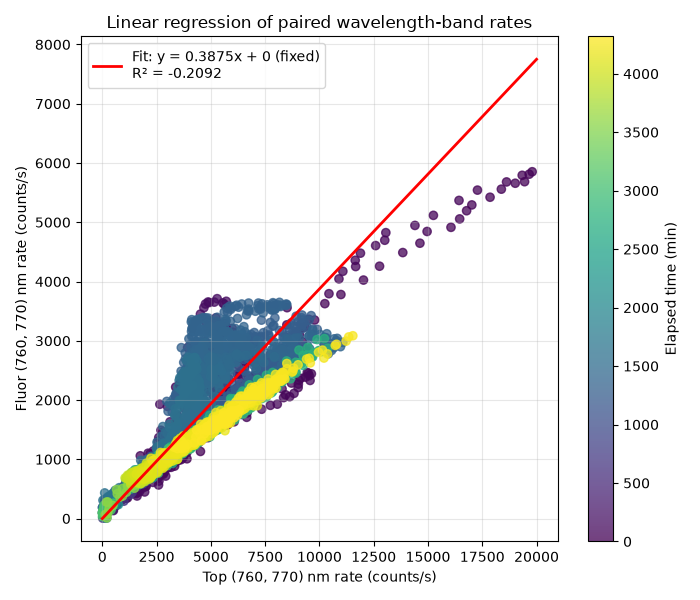

Regression points: 5895 of 11436
Slope: 0.3875
Intercept: 0
R²: -0.209181


In [39]:
fit_x_range = (1000, 2500)
fit_y_range = None
fixed_intercept = 0  # Set to None to fit the intercept freely

fit_mask = (
    np.isfinite(band_pairs["incident_rate"])
    & np.isfinite(band_pairs["fluorescence_rate"])
)

if fit_x_range is not None:
    fit_mask &= band_pairs["incident_rate"].between(*fit_x_range)

if fit_y_range is not None:
    fit_mask &= band_pairs["fluorescence_rate"].between(*fit_y_range)

regression_pairs = band_pairs.loc[fit_mask].copy()

x = regression_pairs["incident_rate"].to_numpy(dtype=float)
y = regression_pairs["fluorescence_rate"].to_numpy(dtype=float)

if len(x) < 2:
    raise ValueError("At least two points are required for linear regression")

if fixed_intercept is None:
    slope, intercept = np.polyfit(x, y, 1)
else:
    intercept = float(fixed_intercept)
    denominator = np.sum(x * x)

    if denominator == 0:
        raise ValueError("Cannot fit a fixed intercept when all x values are zero")

    slope = np.sum(x * (y - intercept)) / denominator

predicted = slope * x + intercept
ss_res = np.sum((y - predicted) ** 2)
ss_total = np.sum((y - y.mean()) ** 2)
r_squared = 1 - ss_res / ss_total if ss_total > 0 else np.nan

# line_min = x.min() if fit_x_range is None else max(fit_x_range[0], x.min())
# line_max = x.max() if fit_x_range is None else min(fit_x_range[1], x.max())

x_fit = np.array([0, 20000])
y_fit = slope * x_fit + intercept

fig, ax = plt.subplots(figsize=(7, 6))

scatter = ax.scatter(
    band_pairs["incident_rate"],
    band_pairs["fluorescence_rate"],
    c=band_pairs["elapsed_min"],
    cmap="viridis",
    alpha=0.75,
)

fit_label = f"Fit: y = {slope:.6g}x"
fit_label += f" + {intercept:.6g}"
fit_label += " (fixed)" if fixed_intercept is not None else ""
fit_label += f"\nR² = {r_squared:.4f}"

ax.plot(
    x_fit,
    y_fit,
    color="red",
    linewidth=2,
    label=fit_label,
)

fig.colorbar(scatter, ax=ax, label="Elapsed time (min)")
ax.set_xlabel(f"{incident_device} {incident_range_nm} nm rate (counts/s)")
ax.set_ylabel(f"{fluorescence_device} {fluorescence_range_nm} nm rate (counts/s)")
ax.set_title("Linear regression of paired wavelength-band rates")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

print(f"Regression points: {len(regression_pairs)} of {len(band_pairs)}")
print(f"Slope: {slope:.6g}")
print(f"Intercept: {intercept:.6g}")
print(f"R²: {r_squared:.6f}")


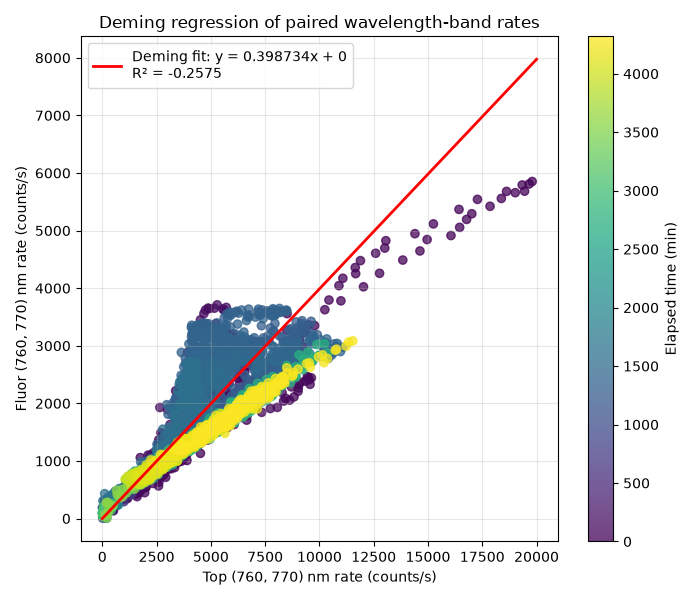

Deming regression points: 4438 of 11436
Delta: 1
Intercept: 0 (fixed)
Slope: 0.398734
R²: -0.257544


In [60]:


# Deming regression of paired incident and fluorescence rates.
fit_x_range = (750, 2000)       # Set to None for no x-range filter
fit_y_range = None               # Example: (100, 1000); None for no y-range filter
line_x_range = (0, 20000)        # Set to fit_x_range to draw the line only across the fit range
deming_delta = 1                 # Ratio of y-error variance to x-error variance
forced_intercept = 0             # Set to None to fit the intercept freely

fit_mask = (
    np.isfinite(band_pairs["incident_rate"])
    & np.isfinite(band_pairs["fluorescence_rate"])
)

if fit_x_range is not None:
    fit_mask &= band_pairs["incident_rate"].between(*fit_x_range)
if fit_y_range is not None:
    fit_mask &= band_pairs["fluorescence_rate"].between(*fit_y_range)

regression_pairs = band_pairs.loc[fit_mask].copy()
x = regression_pairs["incident_rate"].to_numpy(dtype=float)
y = regression_pairs["fluorescence_rate"].to_numpy(dtype=float)

if len(x) < 2:
    raise ValueError("At least two points are required for Deming regression")
if deming_delta <= 0:
    raise ValueError("deming_delta must be positive")

if forced_intercept is None:
    # Standard Deming regression with a freely fitted intercept.
    s_xx, s_xy, s_yy = np.cov(x, y, ddof=1).ravel()[[0, 1, 3]]
    x_mean, y_mean = x.mean(), y.mean()
    intercept_description = "fitted"
else:
    # Deming regression constrained to pass through the chosen intercept.
    y_adjusted = y - float(forced_intercept)
    s_xx = np.sum(x**2)
    s_xy = np.sum(x * y_adjusted)
    s_yy = np.sum(y_adjusted**2)
    x_mean, y_mean = None, None
    intercept_description = "fixed"

if np.isclose(s_xy, 0):
    raise ValueError("Cannot estimate a Deming slope when x-y covariance is zero")

difference = s_yy - deming_delta * s_xx
slope = (
    difference + np.sqrt(difference**2 + 4 * deming_delta * s_xy**2)
) / (2 * s_xy)

intercept = (
    y_mean - slope * x_mean
    if forced_intercept is None
    else float(forced_intercept)
)

# R² is calculated using vertical residuals on the fitted points.
predicted = slope * x + intercept
ss_res = np.sum((y - predicted) ** 2)
ss_total = np.sum((y - y.mean()) ** 2)
r_squared = 1 - ss_res / ss_total if ss_total > 0 else np.nan

line_x = np.asarray(line_x_range, dtype=float)
line_y = slope * line_x + intercept

fig, ax = plt.subplots(figsize=(7, 6))
scatter = ax.scatter(
    band_pairs["incident_rate"],
    band_pairs["fluorescence_rate"],
    c=band_pairs["elapsed_min"],
    cmap="viridis",
    alpha=0.75,
)
ax.plot(
    line_x,
    line_y,
    color="red",
    linewidth=2,
    label=f"Deming fit: y = {slope:.6g}x + {intercept:.6g}\nR² = {r_squared:.4f}",
)
fig.colorbar(scatter, ax=ax, label="Elapsed time (min)")
ax.set_xlabel(f"{incident_device} {incident_range_nm} nm rate (counts/s)")
ax.set_ylabel(f"{fluorescence_device} {fluorescence_range_nm} nm rate (counts/s)")
ax.set_title("Deming regression of paired wavelength-band rates")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

print(f"Deming regression points: {len(regression_pairs)} of {len(band_pairs)}")
print(f"Delta: {deming_delta:g}")
print(f"Intercept: {intercept:.6g} ({intercept_description})")
print(f"Slope: {slope:.6g}")
print(f"R²: {r_squared:.6f}")

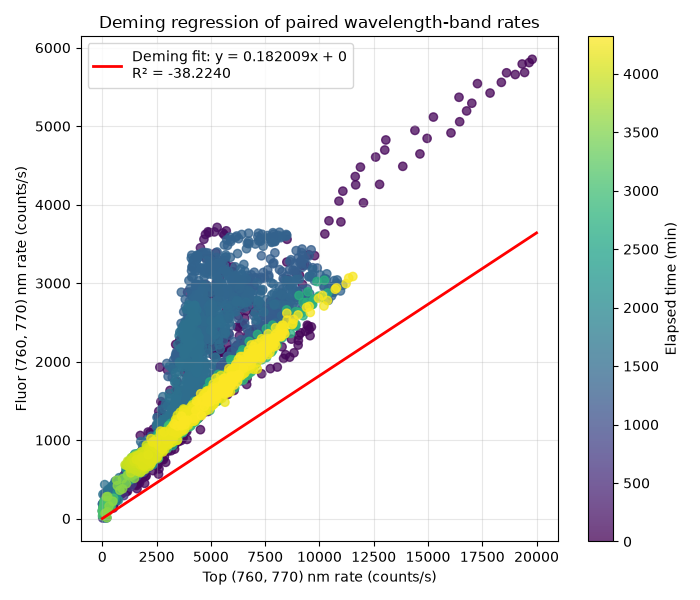

Deming regression points: 5895 of 11436
Delta: 1
Slope: 0.182009
Intercept: 0
R²: -38.223970


TypeError: DataFrame contains columns with dtype datetime64 or timedelta64, which are not supported for cov.

In [49]:
fit_x_range = (1000, 2500)
fit_y_range = None
deming_delta = 1  # Ratio of y-error variance to x-error variance
forced_intercept = 0  # Set to a number to fix the intercept; None fits freely

fit_mask = (
    np.isfinite(band_pairs["incident_rate"])
    & np.isfinite(band_pairs["fluorescence_rate"])
)

if fit_x_range is not None:
    fit_mask &= band_pairs["incident_rate"].between(*fit_x_range)

if fit_y_range is not None:
    fit_mask &= band_pairs["fluorescence_rate"].between(*fit_y_range)

regression_pairs = band_pairs.loc[fit_mask].copy()

x = regression_pairs["incident_rate"].to_numpy(dtype=float)
y = regression_pairs["fluorescence_rate"].to_numpy(dtype=float)

if len(x) < 2:
    raise ValueError("At least two points are required for Deming regression")

if deming_delta <= 0:
    raise ValueError("deming_delta must be positive")

covariance = np.cov(x, y, ddof=1)
s_xx = covariance[0, 0]
s_yy = covariance[1, 1]
s_xy = covariance[0, 1]

if abs(s_xy) < np.finfo(float).eps:
    raise ValueError("Cannot estimate a slope when the covariance is zero")

difference = s_yy - deming_delta * s_xx
discriminant = difference**2 + 4 * deming_delta * s_xy**2

slope = (
    difference + np.sqrt(discriminant)
) / (2 * s_xy)
intercept = y.mean() - slope * x.mean() if forced_intercept is None else forced_intercept

predicted = slope * x + intercept
ss_res = np.sum((y - predicted)**2)
ss_total = np.sum((y - y.mean())**2)
r_squared = 1 - ss_res / ss_total if ss_total > 0 else np.nan

x_fit = np.array([0, 20000])
y_fit = slope * x_fit + intercept

fig, ax = plt.subplots(figsize=(7, 6))

scatter = ax.scatter(
    band_pairs["incident_rate"],
    band_pairs["fluorescence_rate"],
    c=band_pairs["elapsed_min"],
    cmap="viridis",
    alpha=0.75,
)

fit_label = (
    f"Deming fit: y = {slope:.6g}x + {intercept:.6g}"
    f"\nR² = {r_squared:.4f}"
)

ax.plot(
    x_fit,
    y_fit,
    color="red",
    linewidth=2,
    label=fit_label,
)

fig.colorbar(scatter, ax=ax, label="Elapsed time (min)")
ax.set_xlabel(f"{incident_device} {incident_range_nm} nm rate (counts/s)")
ax.set_ylabel(f"{fluorescence_device} {fluorescence_range_nm} nm rate (counts/s)")
ax.set_title("Deming regression of paired wavelength-band rates")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

print(f"Deming regression points: {len(regression_pairs)} of {len(band_pairs)}")
print(f"Delta: {deming_delta:.6g}")
print(f"Slope: {slope:.6g}")
print(f"Intercept: {intercept:.6g}")
print(f"R²: {r_squared:.6f}")

if fit_y_range is not None:
    fit_mask &= band_pairs["fluorescence_rate"].between(*fit_y_range)

regression_pairs = band_pairs.loc[fit_mask].copy()

x = regression_pairs["incident_rate"].to_numpy(dtype=float)
y = regression_pairs["fluorescence_rate"].to_numpy(dtype=float)

def deming_regression(df, x, y, delta = 1):
#'''Takes a pandas DataFrame, name of the 
#columns as strings and the value of delta, 
#and returns the slope and intercept following deming regression formula'''

    cov = df.cov()
    mean_x = df[x].mean()
    mean_y = df[y].mean()
    s_xx = cov[x][x]
    s_yy = cov[y][y]
    s_xy = cov[x][y]

    slope = (s_yy  - delta * s_xx + np.sqrt((s_yy - delta * s_xx) ** 2 + 4 * delta * s_xy ** 2)) / (2 * s_xy)

    intercept = mean_y - slope  * mean_x

    return slope, intercept

deming_regression(regression_pairs, "incident_rate", "fluorescence_rate", delta=1)

In [ ]:
band_pairs.columns

Index(['session_id', 'tick', 'Fluor', 'Top', 'timestamp', 'par_rate',
       'rate_ratio', 'timestamp_local', 'elapsed_min'],
      dtype='str')

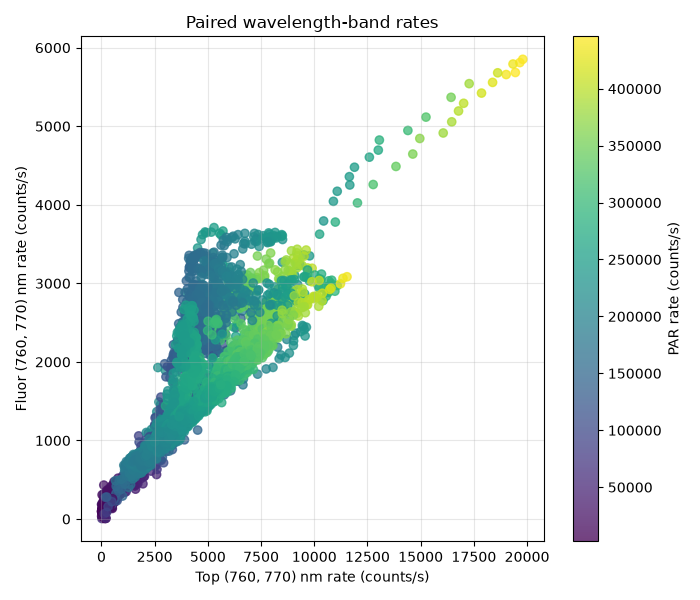

In [13]:
# Compare incident and fluorescence band rates.
band_pairs = paired.dropna(subset=["incident_rate", "fluorescence_rate"]).copy()
band_pairs["elapsed_min"] = (
    band_pairs["timestamp"] - band_pairs["timestamp"].min()
).dt.total_seconds() / 60
fig, ax = plt.subplots(figsize=(7, 6))
scatter = ax.scatter(
    band_pairs["incident_rate"], band_pairs["fluorescence_rate"],
    c=band_pairs["par_rate"],
    cmap="viridis", alpha=0.75,
)
fig.colorbar(scatter, ax=ax, label="PAR rate (counts/s)")
ax.set_xlabel(f"{incident_device} {incident_range_nm} nm rate (counts/s)")
ax.set_ylabel(f"{fluorescence_device} {fluorescence_range_nm} nm rate (counts/s)")
ax.set_title("Paired wavelength-band rates")
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()


## Interpreting the plots

The band plots use counts per second: each spectrum's counts are divided by that spectrum's own integration time before plotting or summing a wavelength band. This corrects for different exposure durations, but does not correct differences in detector gain or spectral response. The PAR trace sums the Top sensor's pixels from 400-700 nm on a separate right-hand axis. The ratio is fluorescence-band rate divided by incident-band rate for matching `session_id` and `tick`; it is still not an absolute fluorescence yield.

Dark subtraction is applied pixel-by-pixel before wavelength bands and blocks are summed. Each dark row's `counts_mean` is divided by its own integration time, and dark rates are averaged per sensor, gain setting, and wavelength grid across the full download. A spectrum without a matching dark profile causes an explicit error. Negative corrected rates are retained rather than clipped, since they can result from measurement noise. This correction removes the measured baseline but does not correct differences in detector gain or spectral response.